AUTORIZADO + CARTÃO MESTRE + Almoço
- CPFs distintos: 8
- Total de refeições: 48,554
- Média por CPF: 6069.2
- Mediana: 83.5
- Desvio padrão: 16948.7
- Mínimo: 1
- Máximo: 48015
- Participação: 2.46%

AUTORIZADO + CARTÃO MESTRE + Café da Manhã
- CPFs distintos: 1
- Total de refeições: 6,291
- Média por CPF: 6291.0
- Mediana: 6291.0
- Desvio padrão: nan
- Mínimo: 6291
- Máximo: 6291
- Participação: 0.32%

AUTORIZADO + CARTÃO MESTRE + Jantar
- CPFs distintos: 4
- Total de refeições: 20,567
- Média por CPF: 5141.8
- Mediana: 76.5
- Desvio padrão: 10170.9
- Mínimo: 16
- Máximo: 20398
- Participação: 1.04%

AUXILIO_CONCLUDENTE + NÃO PAGANTE + Almoço
- CPFs distintos: 20
- Total de refeições: 111
- Média por CPF: 5.5
- Mediana: 5.5
- Desvio padrão: 3.2
- Mínimo: 1
- Máximo: 10
- Participação: 0.01%

AUXILIO_CONCLUDENTE + NÃO PAGANTE + Jantar
- CPFs distintos: 8
- Total de refeições: 39
- Média por CPF: 4.9
- Mediana: 3.5
- Desvio padrão: 3.8
- Mínimo: 1
- Máximo: 12
- Participação: 0.00%

AU

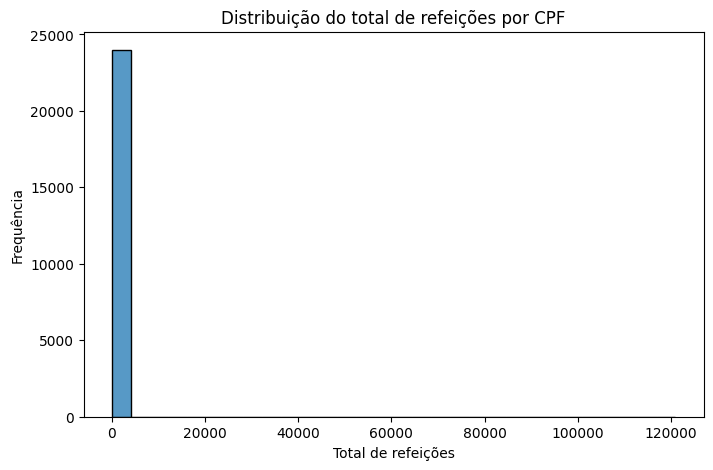

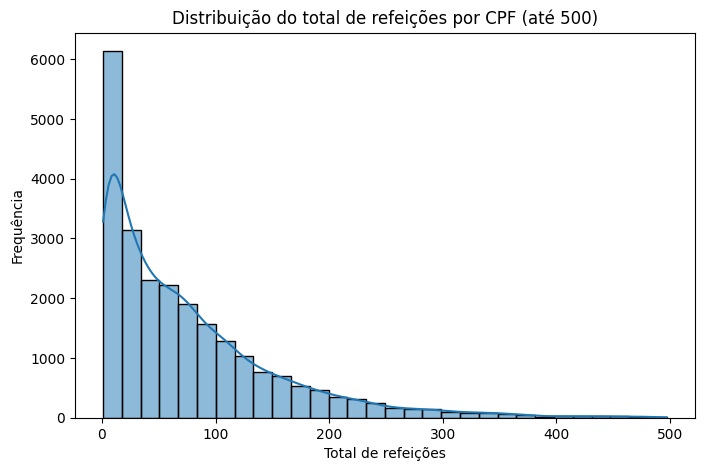

/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 23977.
  res = hypotest_fun_out(*samples, **kwds)


Estatística do teste Shapiro-Wilk = 0.0147, p-valor = 0.0000
Distribuição não é normal.

Probabilidade de uma pessoa na fila do almoço ser não-pagante: 33.27%
Probabilidade de um docente ter jantado dado que almoçou: 20.00%
Index(['cpf_cnpj', 'vinculo_comensal', 'categoria_acesso', 'tipo_refeicao',
       'quantidade_refeicao'],
      dtype='object')
      cpf_cnpj vinculo_comensal categoria_acesso tipo_refeicao  \
0  ***425413**  ISENCAO_PARCIAL      NÃO PAGANTE        Almoço   
1  ***425413**  ISENCAO_PARCIAL      NÃO PAGANTE        Jantar   
2  ***492743**         DISCENTE          PAGANTE        Almoço   
3  ***492743**         DISCENTE          PAGANTE        Jantar   
4  ***603453**         DISCENTE          PAGANTE        Almoço   

   quantidade_refeicao  
0                   93  
1                   23  
2                   82  
3                   13  
4                    1  


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro

# Leitura do arquivo CSV
df = pd.read_csv("https://raw.githubusercontent.com/bhpp12/datasets/refs/heads/main/17_prae_comensais_2024.csv")

# --Parte 1 --

# Cria uma nova coluna 'perfil' que combina informações de vínculo, categoria e tipo de refeição. O uso de astype(str) evita erros se houver valores ausentes (NaN)
df["perfil"] = (
    df["vinculo_comensal"].astype(str) + " + " +
    df["categoria_acesso"].astype(str) + " + " +
    df["tipo_refeicao"].astype(str)
)

# Cria um resumo agrupando o DataFrame por perfil. Para cada grupo, são calculadas diversas estatísticas descritivas sobre o número de refeições
resumo = df.groupby("perfil").agg(
    cpfs_distintos = ("cpf_cnpj", "nunique"), # Número de cpfs unicos
    total_refeicoes = ("quantidade_refeicao", "sum"), # Total de refeições
    media_refeicoes = ("quantidade_refeicao", "mean"), # Média das refeições
    mediana_refeicoes = ("quantidade_refeicao", "median"), # Mediana
    desvio_refeicoes = ("quantidade_refeicao", "std"), # Desvio padrão
    min_refeicoes = ("quantidade_refeicao", "min"), # Menor valor de refeição
    max_refeicoes = ("quantidade_refeicao", "max") # Maior valor de refeição
).reset_index()

# Calcula a porcentagem que cada perfil representa no total de refeições
total_geral = resumo["total_refeicoes"].sum()
resumo["participacao_%"] = (resumo["total_refeicoes"] / total_geral) * 100

# Exibe o resumo com formatação mais legível
for _, linha in resumo.iterrows():
    print(f"{linha['perfil']}")
    print(f"- CPFs distintos: {linha['cpfs_distintos']}")
    print(f"- Total de refeições: {linha['total_refeicoes']:,}")
    print(f"- Média por CPF: {linha['media_refeicoes']:.1f}")
    print(f"- Mediana: {linha['mediana_refeicoes']}")
    print(f"- Desvio padrão: {linha['desvio_refeicoes']:.1f}")
    print(f"- Mínimo: {linha['min_refeicoes']}")
    print(f"- Máximo: {linha['max_refeicoes']}")
    print(f"- Participação: {linha['participacao_%']:.2f}%\n")

# --Parte 2 --

# Soma o número total de refeições por CPF individual
refeicao_por_cpf = df.groupby("cpf_cnpj")["quantidade_refeicao"].sum()

# Cria o primeiro histograma com todos os dados
plt.figure(figsize=(8,5))
sns.histplot(refeicao_por_cpf, bins=30, kde=False)
plt.title("Distribuição do total de refeições por CPF")
plt.xlabel("Total de refeições")
plt.ylabel("Frequência")
plt.show()

# OBS: A frequência é alta porque muitos CPFs aparecem poucas vezes ou seja,há muitos indivíduos com poucas refeições registradas. Isso faz o histograma ter uma concentração enorme no início do eixo X (exemplo: 1 a 10 refeições).

# Cria um segundo histograma, agora limitando o eixo X até 500 refeições. Isso ajuda a visualizar melhor a distribuição, eliminando os outliers que distorcem a escala.
plt.figure(figsize=(8,5))
sns.histplot(refeicao_por_cpf[refeicao_por_cpf < 500], bins=30, kde=True)
plt.title("Distribuição do total de refeições por CPF (até 500)")
plt.xlabel("Total de refeições")
plt.ylabel("Frequência")
plt.show()

# Teste de normalidade (Shapiro-Wilk) para verificar se a distribuição é aproximadamente normal. Se p > 0.05 os dados seguem distribuição normal. Se p ≤ 0.05 é anormal.
stat, p = shapiro(refeicao_por_cpf)
print(f"Estatística do teste Shapiro-Wilk = {stat:.4f}, p-valor = {p:.4f}")

if p > 0.05:
    print("Distribuição aproximadamente normal.")
else:
    print("Distribuição não é normal.")

# -- Parte 3 --

# Filtra os registros de almoço
almoco = df[df["tipo_refeicao"].str.lower() == 'almoço']

# Filtra os não pagantes dentro do subconjunto de almoço e soma as refeições desses registros
nao_pagantes = almoco[almoco["categoria_acesso"].str.lower() == ("não pagante")]["quantidade_refeicao"].sum()

# Calcula a quantidade total de refeições de almoço
total_almoco = almoco["quantidade_refeicao"].sum()

# Calcula a probabilidade de uma pessoa na fila ser não pagante
probabilidade_nao_pagante = nao_pagantes / total_almoco

print(f"\nProbabilidade de uma pessoa na fila do almoço ser não-pagante: {probabilidade_nao_pagante:.2%}")

#-- Parte 4 --

# CPFs de docentes que almoçaram (usamos set para evitar duplicatas)
docente_almoco = set(df[(df["vinculo_comensal"].str.lower() == "docente") &
                    (df["tipo_refeicao"].str.lower() == "almoço")]["cpf_cnpj"])

# CPFs de docentes que jantaram
docente_jantar = set(df[(df["vinculo_comensal"].str.lower() == "docente") &
                    (df["tipo_refeicao"].str.lower() == "jantar")]["cpf_cnpj"])


docente_interseccao = docente_almoco.intersection(docente_jantar)

# Probabilidade condicional P(B | A) = |A ∩ B| / |A|. Onde A = Almoçar e B = Jantar
probabilidade_docente_jantou_dado_almocou = len(docente_interseccao) / len(docente_almoco)
print(f"Probabilidade de um docente ter jantado dado que almoçou: {probabilidade_docente_jantou_dado_almocou:.2%}")


import pandas as pd

df = pd.read_csv("https://raw.githubusercontent.com/bhpp12/datasets/refs/heads/main/17_prae_comensais_2024.csv")

print(df.columns)
print(df.head())